In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("Sales.csv")

* There are 8 numeric and 2 categorical column

In [ ]:
data.describe()

,Advertising Expenditure,Campaign Engagement Score,Discount Percentage,Average Customer Rating,Product Price,Return Rate,Length of Product Description,Sales
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,607.727150,49.456305,28.997927,4.408783,1434.718134,1.666106,248.696636,23858.638609
std,82.025112,13.171290,4.700923,0.227823,222.832467,0.900435,60.800024,3611.748810
min,97.250000,0.000000,0.000000,3.649450,9.780000,0.033720,42.000000,3257.595426
25%,561.984787,40.697530,26.222998,4.251118,1306.155958,0.954551,207.076217,21632.968838
50%,616.116596,49.478699,29.552853,4.432254,1461.301831,1.537856,249.348398,24087.129995
75%,666.331853,58.150891,32.259294,4.583205,1587.671790,2.285394,288.875650,26421.772433
max,801.500000,98.750000,40.540000,4.874450,2000.560000,4.534866,496.000000,34421.427430


In [ ]:
data.info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Advertising Expenditure        3000 non-null   float64
 1   Campaign Engagement Score      3000 non-null   float64
 2   Discount Percentage            3000 non-null   float64
 3   Average Customer Rating        3000 non-null   float64
 4   Product Price                  3000 non-null   float64
 5   Return Rate                    3000 non-null   float64
 6   Length of Product Description  3000 non-null   float64
 7   Region                         3000 non-null   object 
 8   Popularity                     3000 non-null   object 
 9   Sales                          3000 non-null   float64
dtypes: float64(8), object(2)
memory usage: 234.5+ KB


EDA 

Univariate 

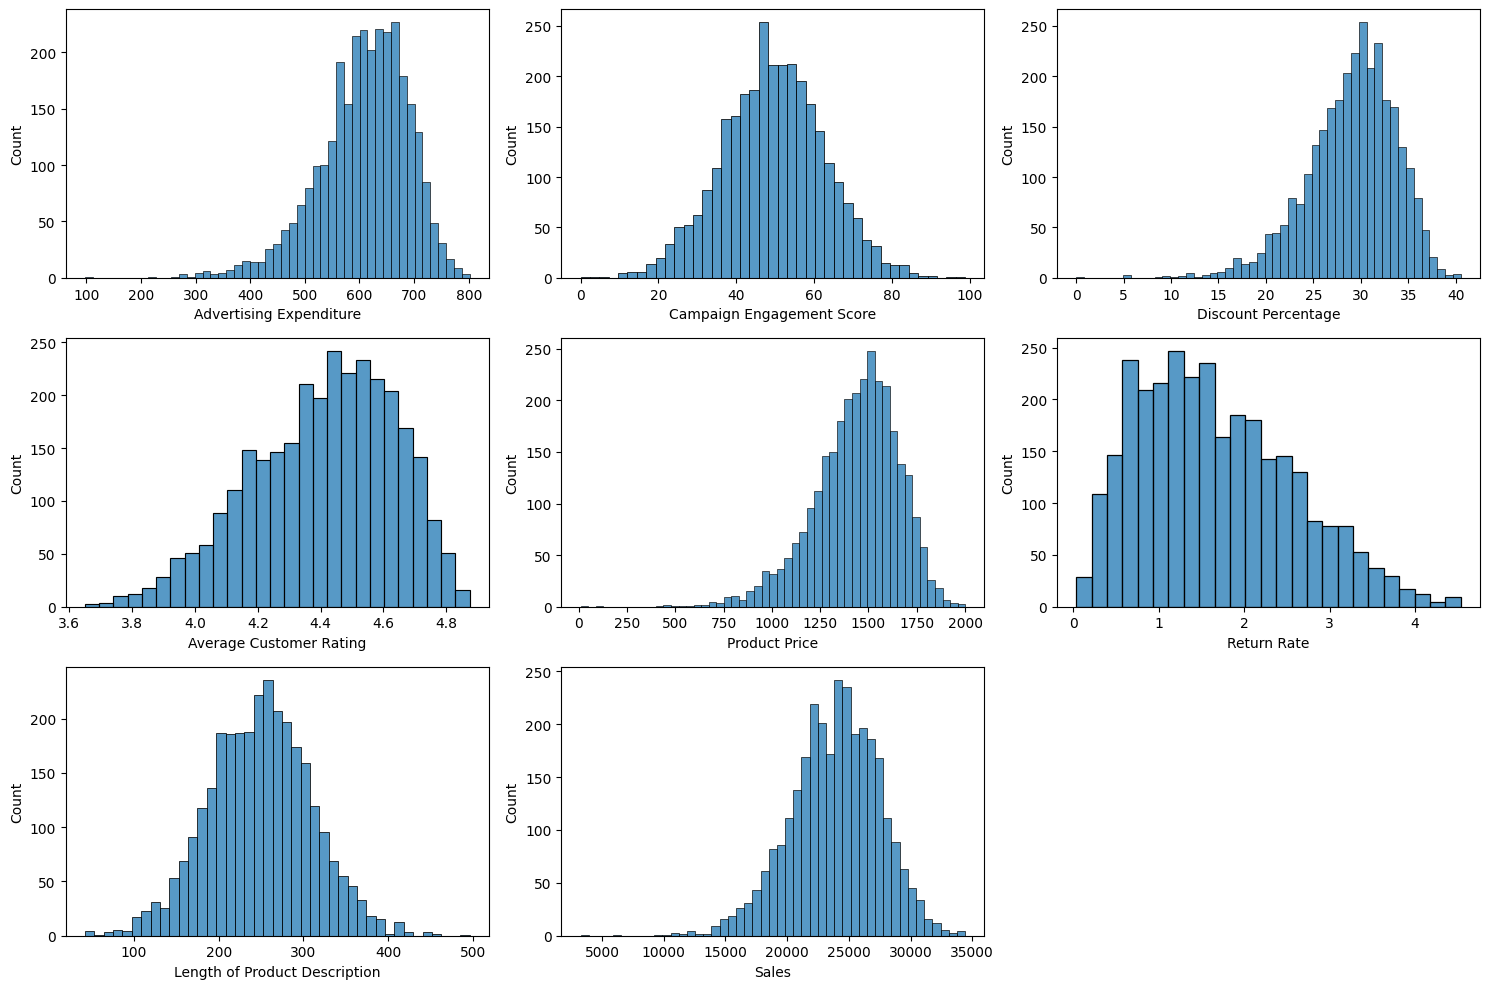

In [16]:
plt.figure(figsize=(15,10))
features = data.select_dtypes(include=['number']).columns.tolist()
for i, feature in enumerate(features):
    plt.subplot(3,3,i+1)
    sns.histplot(data=data,x=feature)

plt.tight_layout() # to add spacing between plotsd
plt.show()

* left-skew 

Mean < Median

"The advertising expenditure distribution is left-skewed, indicating that most observations have relatively high advertising spending, while a small number of observations with very low spending pull the mean downward."

in that type of scene 

5, 80, 85, 90, 95



* Sales, Advertising Expenditure, Discount Percentage,and Product Price exhibit left-skewed distribution

* Return Rate exhibits a right-skewed distribution

* Campaign Engagement Score and Length of Product Description are approx normally distributed

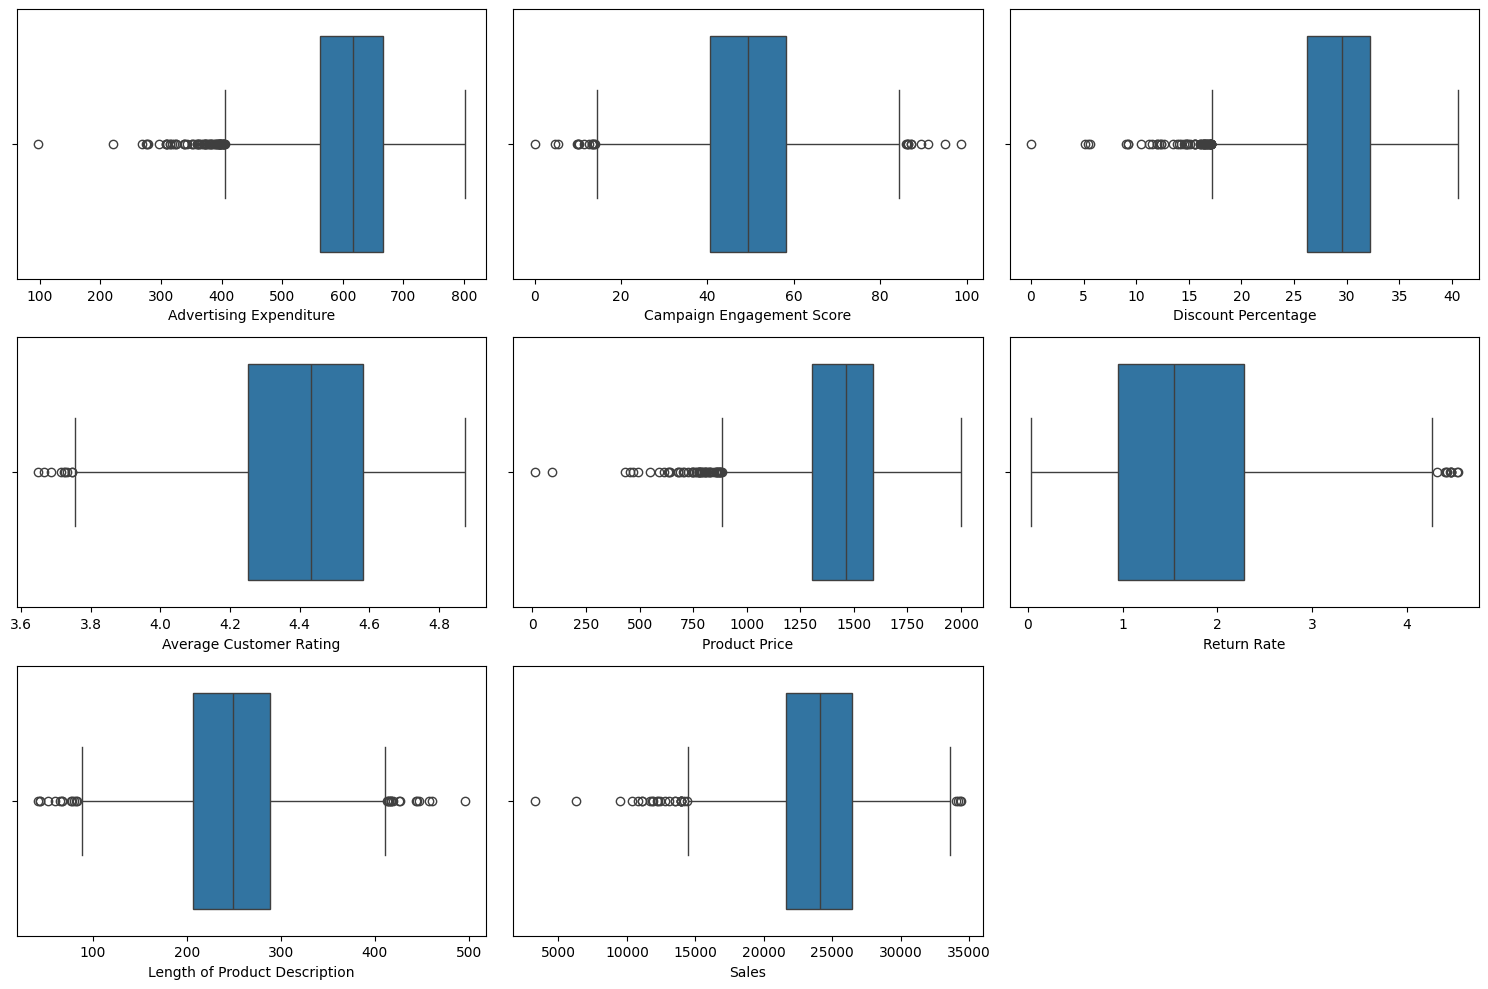

In [18]:
plt.figure(figsize=(15,10))
features = data.select_dtypes(include=['number']).columns.tolist()

for i,feature in enumerate(features):
    plt.subplot(3,3,i+1)
    sns.boxplot(data=data,x=feature)
plt.tight_layout()
plt.show()

* There are outlier in all attribute data s

In [19]:
data[data['Advertising Expenditure'] < 400]

,Advertising Expenditure,Campaign Engagement Score,Discount Percentage,Average Customer Rating,Product Price,Return Rate,Length of Product Description,Region,Popularity,Sales
23,396.631709,31.508022,23.883722,4.490895,1189.210278,1.901168,234.509577,East,High,14165.412860
53,351.568112,31.184396,26.701090,4.055964,1475.701838,1.052501,364.068006,East,Low,11942.031310
82,371.763742,26.606690,26.284415,4.557851,742.134362,1.902833,215.908306,West,High,25085.011080
105,374.267758,43.934858,26.464778,4.606144,1373.016007,1.160337,221.420611,South,High,16373.574940
119,324.209660,44.782380,20.498618,4.480142,1286.903785,1.013704,201.752979,East,Very High,16197.504090
143,318.571514,42.541540,27.880618,4.468156,1465.130424,2.302143,253.173660,South,Very High,11134.995970
205,394.737975,33.523488,29.455398,4.504206,1349.307787,1.886883,180.934673,East,Very High,15097.384530
214,371.617709,18.648402,32.411618,4.610452,1032.406834,1.286569,238.946301,South,High,20155.038680
233,338.580044,40.358336,17.099989,4.172419,1337.782111,2.340481,254.294584,East,Low,14840.366970
250,308.978215,10.262097,24.942987,4.099082,1115.695596,0.818787,169.676896,East,Low,13939.422920


Categorical features

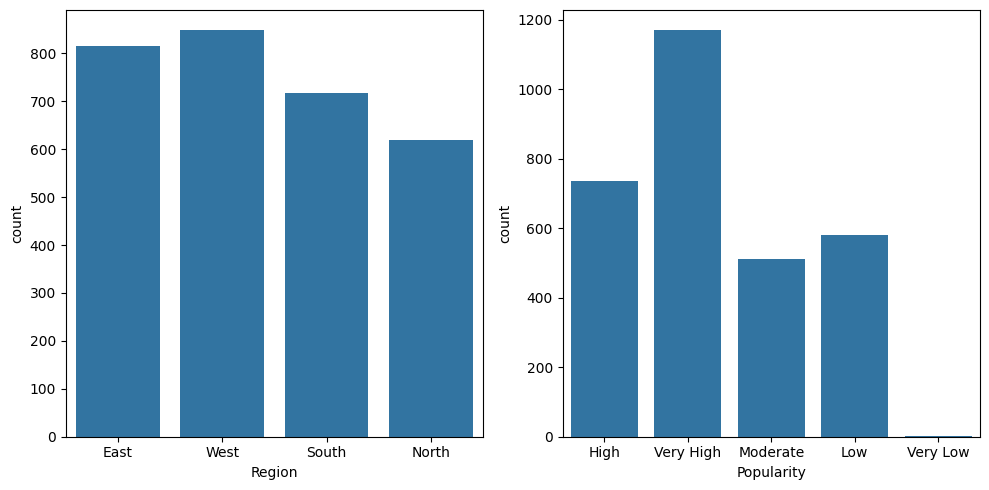

In [21]:
plt.figure(figsize=(10,5))
features = data.select_dtypes(exclude=['number']).columns.tolist()

for i,feature in enumerate(features):
    plt.subplot(1,2,i+1)
    sns.countplot(data=data,x=feature)
plt.tight_layout()
plt.show()

Bivariate Analysis

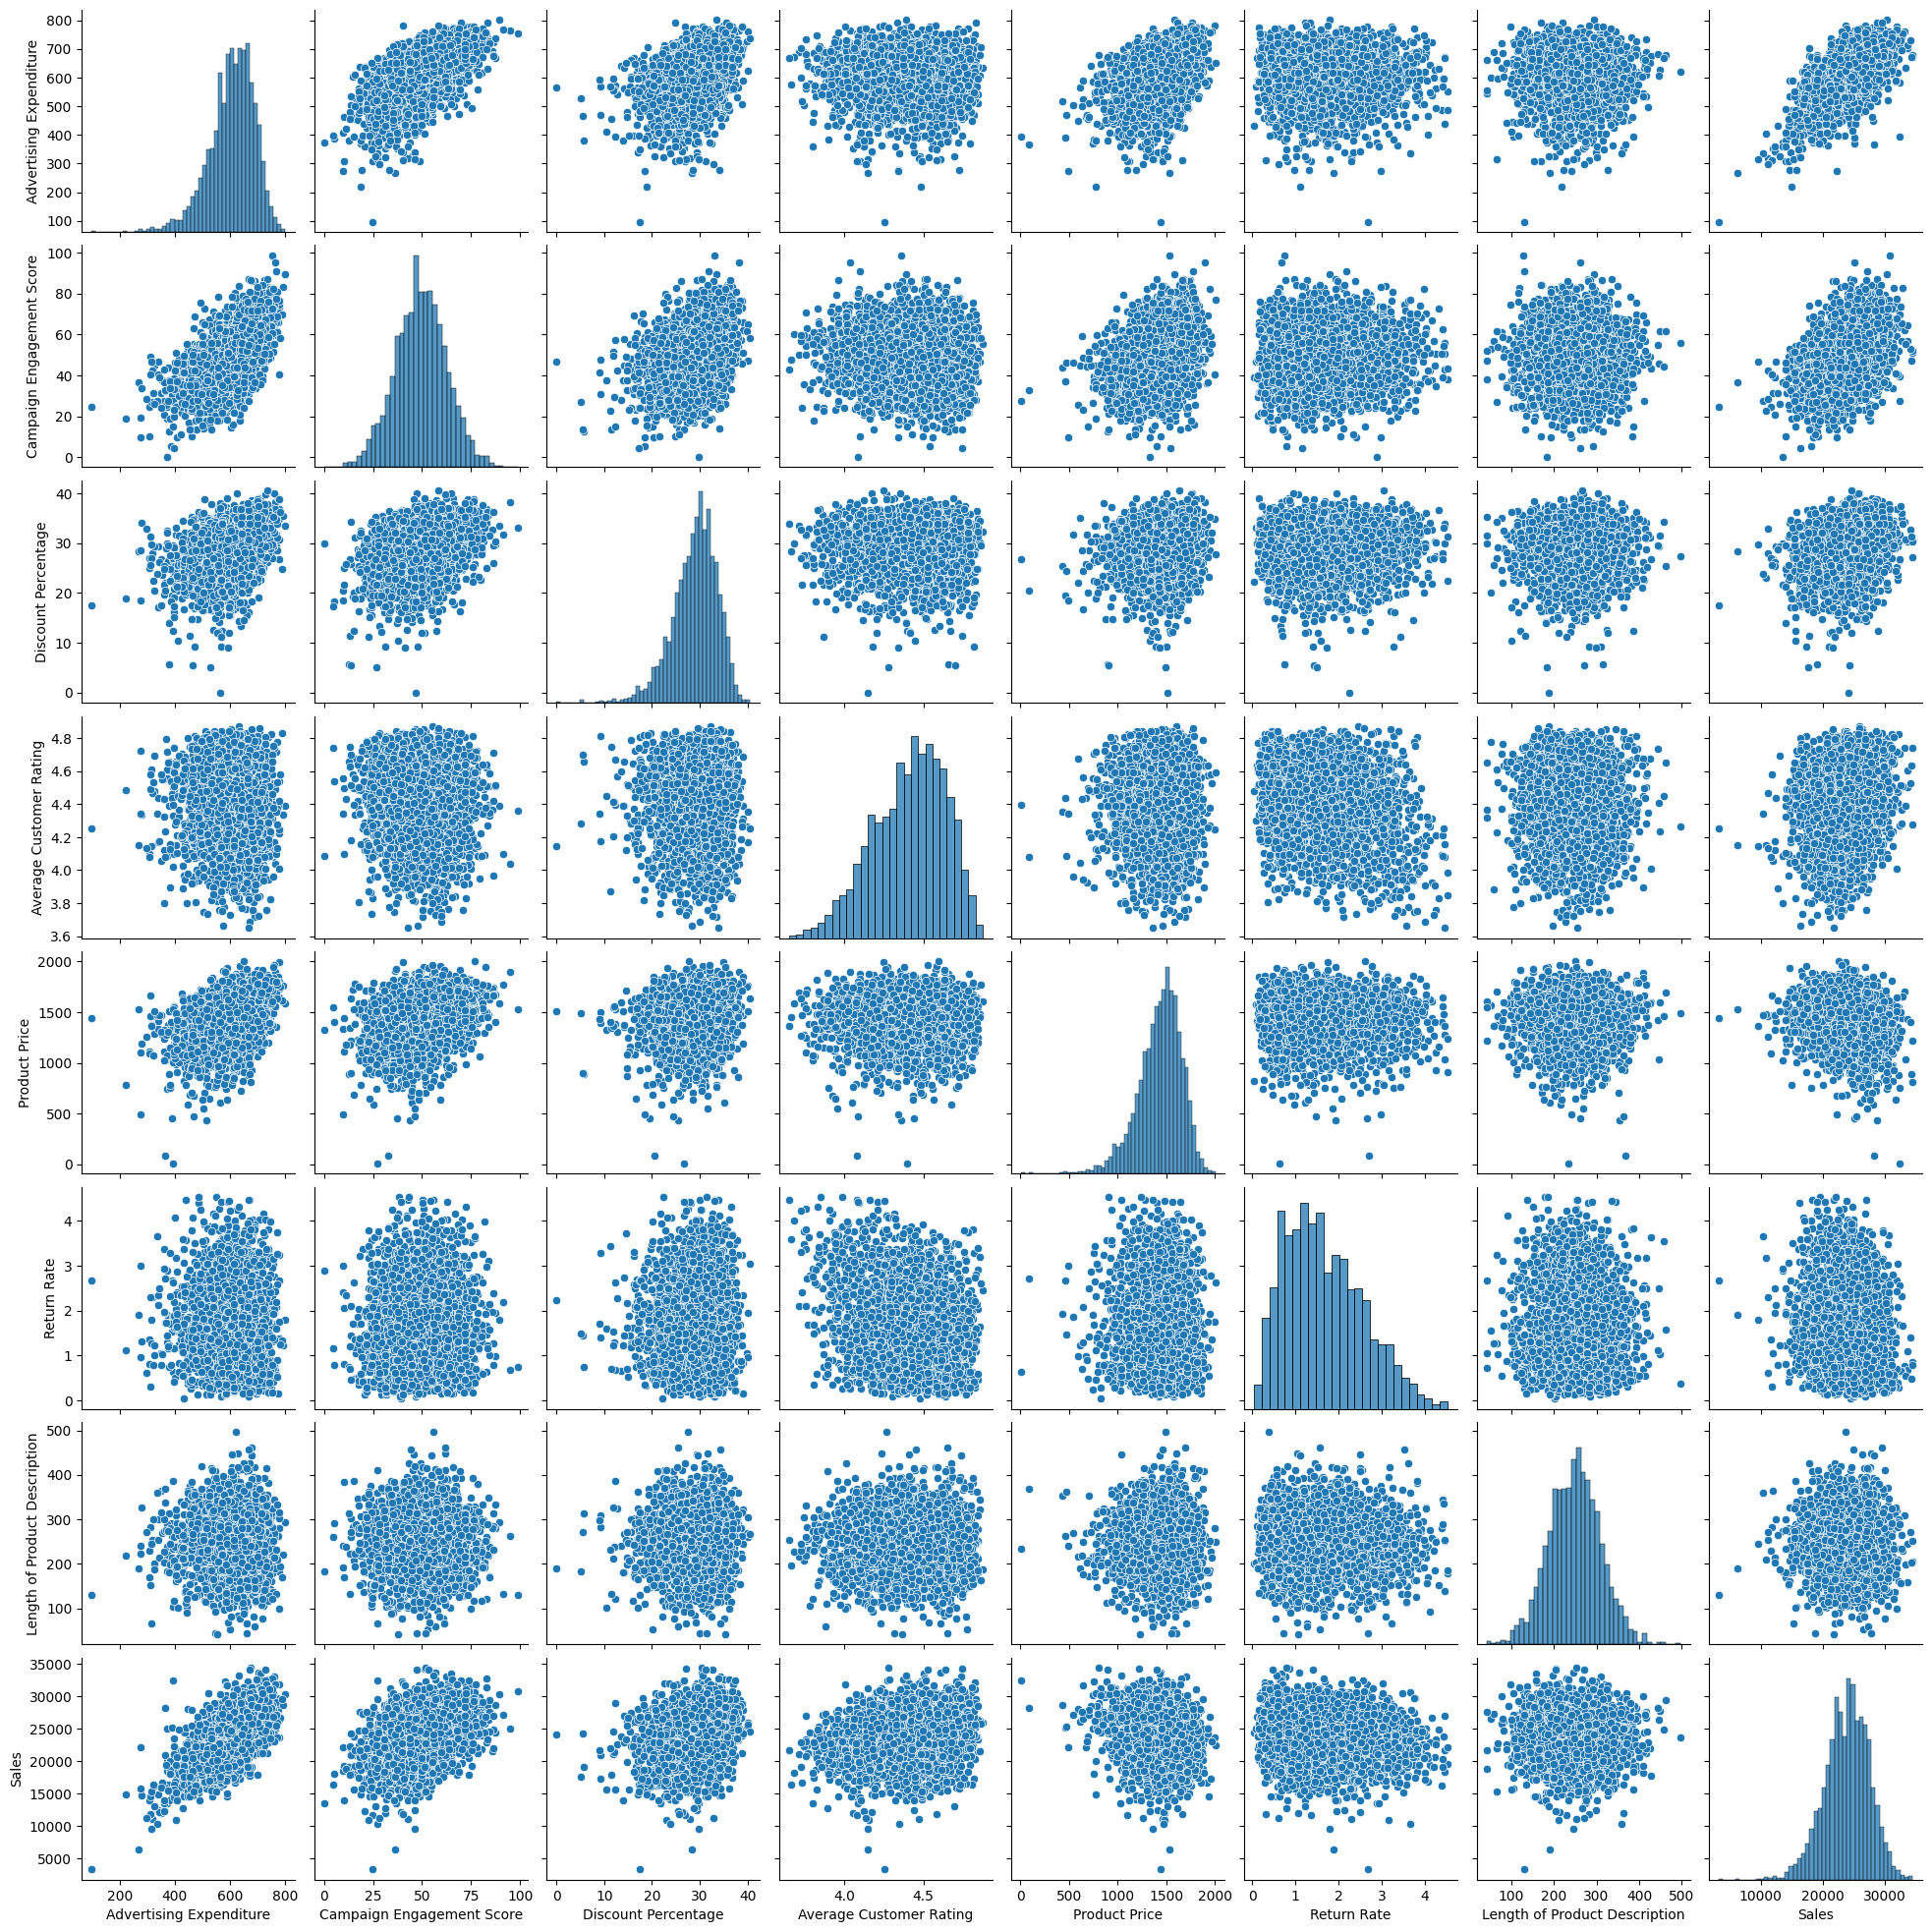

In [22]:
sns.pairplot(data)

* sales seem to be positively correlated with Advertising Expenditure,Campaign Engagement Score,and Average Customer Rating
* Sales seem to be negatively correlated with Product Price and Return Rate

up pos down neg middle no correlation

<Axes: >

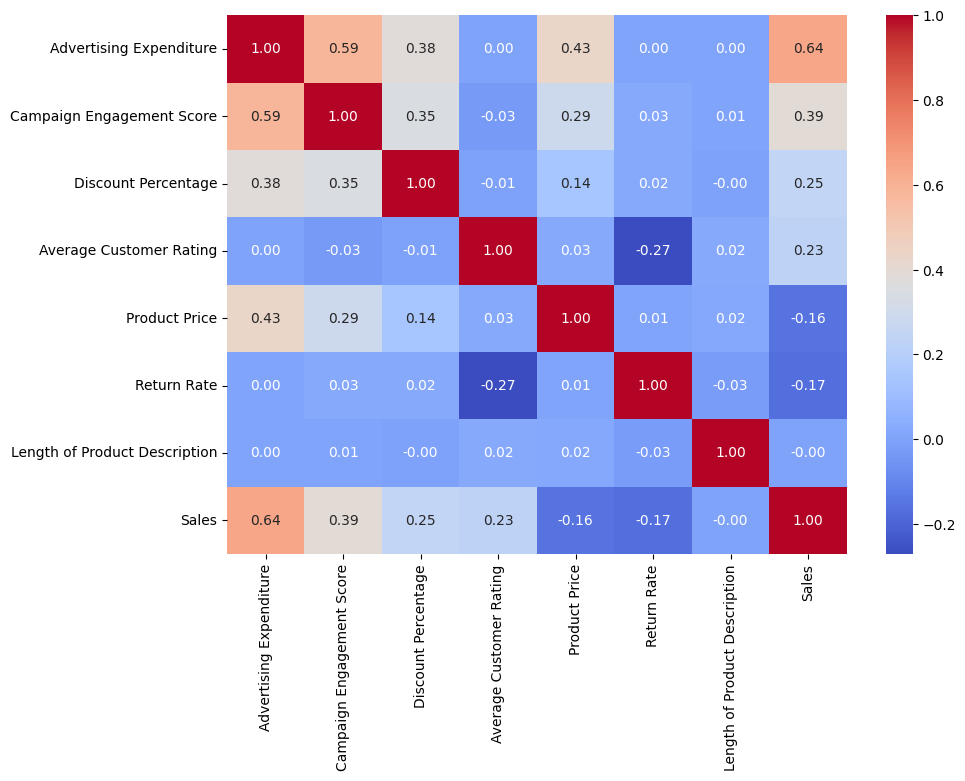

In [23]:
plt.figure(figsize=(10,7))
sns.heatmap(data.corr(numeric_only=True),annot=True,fmt='0.2f',cmap='coolwarm')

<Axes: xlabel='Popularity', ylabel='Sales'>

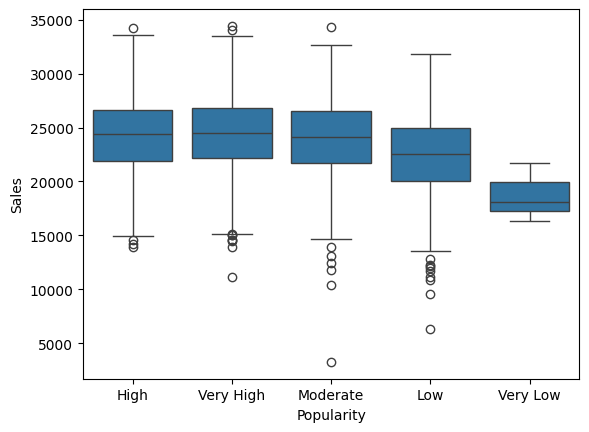

In [24]:
sns.boxplot(data=data,y='Sales',x='Popularity')

<Axes: xlabel='Sales', ylabel='Region'>

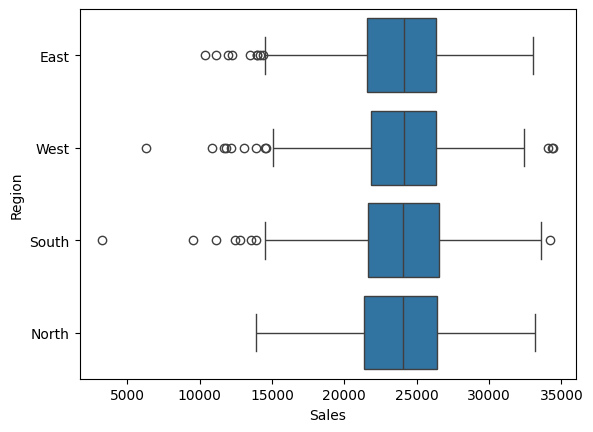

In [26]:
sns.boxplot(data=data,x='Sales',y='Region')

Data Preparation for Modeling

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 


In [5]:
X = data.drop('Sales',axis=1)
y = data['Sales']

In [5]:
X.head()


,Advertising Expenditure,Campaign Engagement Score,Discount Percentage,Average Customer Rating,Product Price,Return Rate,Length of Product Description,Region,Popularity
0,644.049317,54.565531,25.267151,4.604634,1599.575723,2.133580,231.185389,East,High
1,521.483294,46.875226,35.075859,4.358693,1586.464404,1.553437,262.686931,West,Very High
2,540.079510,42.287145,12.618381,4.571018,1301.644856,2.274891,324.347319,South,Very High
3,627.938419,61.825441,31.588445,4.234209,1601.041884,1.035971,447.710984,South,Very High
4,471.149948,31.061512,9.198991,4.816215,1496.734345,3.276840,310.055333,East,Moderate


In [30]:
y.head()

0    26246.91291
1    21432.16935
2    22551.92436
3    27792.29446
4    17354.77148
Name: Sales, dtype: float64

In [8]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state = 42

)

Model Building

Simple Linear Regression - Sales vs Advertising Expenditure

In [32]:
# defining the independent varible
ind_vars1 = ['Advertising Expenditure']

In [34]:
# creating an instance of the linear regression model
lin_reg1 = LinearRegression()
lin_reg1.fit(X_train[ind_vars1],y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[28.67]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Advertising Expenditure']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6436
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [36]:
data['Advertising Expenditure'].head()

0    644.049317
1    521.483294
2    540.079510
3    627.938419
4    471.149948
Name: Advertising Expenditure, dtype: float64

In [37]:
data['Sales'].head()

0    26246.91291
1    21432.16935
2    22551.92436
3    27792.29446
4    17354.77148
Name: Sales, dtype: float64

In [38]:
print(
    "Slope:",lin_reg1.coef_,
    "Intercept:",lin_reg1.intercept_,
)

Slope: [28.66748755] Intercept: 6435.891302271026


In [40]:
print(
    "Sales = ",
    "(",lin_reg1.coef_[0],")","*",ind_vars1[0],
    "+",lin_reg1.intercept_,
)

Sales =  ( 28.667487552010247 ) * Advertising Expenditure + 6435.891302271026


simple interpretation could be 

if Advertising Expenditure increases by 1 unit, the predicted Sales increase by approximately 28.67 units,on average

Intercept is the value of y when x is zero 

if no money is spent on advertising, the expected sales are about 6436 units.

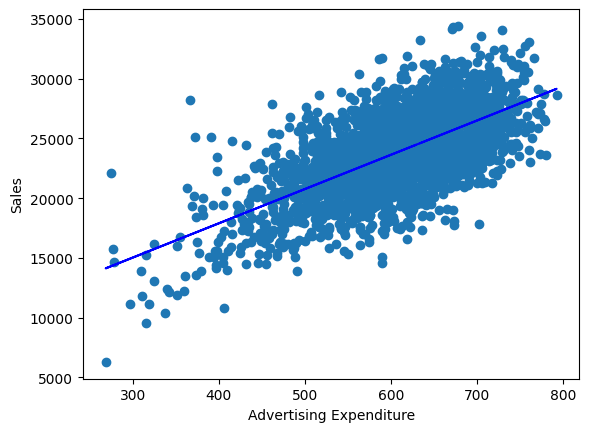

In [42]:
fitted_values1 = lin_reg1.predict(X_train[ind_vars1])

# plot the scatterplot and regression line
plt.scatter(X_train[ind_vars1],y_train)
plt.plot(X_train[ind_vars1],fitted_values1,color='blue')
plt.xlabel(ind_vars1[0])
plt.ylabel('Sales')
plt.show()

In [56]:
ind_vars2 = ['Discount Percentage']
lin_reg2 = LinearRegression()
lin_reg2.fit(X_train[ind_vars2],y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[188.39]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Discount Percentage']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.841e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [57]:
print(
    "Slope:",lin_reg2.coef_,
    "Intercept:",lin_reg2.intercept_,
)

Slope: [188.3855554] Intercept: 18411.681879531294


if Discount increase by 1 Sales will increase by 188

In [59]:
ind_vars3 = ['Product Price']

lin_reg3 = LinearRegression()
lin_reg3.fit(X_train[ind_vars3],y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-2.54]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Product Price']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.752e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


If the Product price increases by 1rs Sales expected to decrease by about 2.54

Encode

In [6]:
lab_enc = {
    'Very Low':1,
    'Low':2,
    'Moderate':3,
    'High':4,
    'Very High':5
}

In [7]:
#  encoding the Popularity column
X['Popularity'] = X['Popularity'].map(
    lambda x: lab_enc[x]
)


In [8]:
X.head()

,Advertising Expenditure,Campaign Engagement Score,Discount Percentage,Average Customer Rating,Product Price,Return Rate,Length of Product Description,Region,Popularity
0,644.049317,54.565531,25.267151,4.604634,1599.575723,2.133580,231.185389,East,4
1,521.483294,46.875226,35.075859,4.358693,1586.464404,1.553437,262.686931,West,5
2,540.079510,42.287145,12.618381,4.571018,1301.644856,2.274891,324.347319,South,5
3,627.938419,61.825441,31.588445,4.234209,1601.041884,1.035971,447.710984,South,5
4,471.149948,31.061512,9.198991,4.816215,1496.734345,3.276840,310.055333,East,3


In [9]:
X = pd.get_dummies(
    X,
    columns = X.select_dtypes(include=["object","category"]).columns.tolist(),
    drop_first=True
)

X = X.astype(float)
X.head()
# drop first is True that's why Region_East delete
# so it easy if 0 0 0 in North South West we'll understand belong to East


,Advertising Expenditure,Campaign Engagement Score,Discount Percentage,Average Customer Rating,Product Price,Return Rate,Length of Product Description,Popularity,Region_North,Region_South,Region_West
0,644.049317,54.565531,25.267151,4.604634,1599.575723,2.133580,231.185389,4.0,0.0,0.0,0.0
1,521.483294,46.875226,35.075859,4.358693,1586.464404,1.553437,262.686931,5.0,0.0,0.0,1.0
2,540.079510,42.287145,12.618381,4.571018,1301.644856,2.274891,324.347319,5.0,0.0,1.0,0.0
3,627.938419,61.825441,31.588445,4.234209,1601.041884,1.035971,447.710984,5.0,0.0,1.0,0.0
4,471.149948,31.061512,9.198991,4.816215,1496.734345,3.276840,310.055333,3.0,0.0,0.0,0.0


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
lin_reg7 = LinearRegression()
lin_reg7.fit(X_train,y_train)